# Детекция и сегментация. Влияние входного разрешения

**Мотыгуллин Булат Габдулхакович**  
**Группа: Б01-301г**  
**Вариант: 11**

In [1]:
from course import *

seed_all(11)
OUT = ROOT / "results" / "08_detection_resolution"
OUT.mkdir(exist_ok=True, parents=True)

## Данные, модель и разметка

Penn-Fudan Pedestrians: фотографии и маски людей. Детектор — SSDlite MobileNetV3-Large с весами COCO, person = 1. U-Net обучаю на отдельной части Penn-Fudan. Размеры входа заданы до оценки.

,input_size,TP,FP,FN,precision,recall,mean_matched_IoU,median_ms,observed_peak_RSS_MB
0,192,0,30,30,0.00000,0.00000,0.00000,40.45410,690.73438
1,256,23,4,7,0.85185,0.76667,0.66460,42.80398,692.67188
2,320,25,3,5,0.89286,0.83333,0.88809,47.41319,703.29688
3,384,26,3,4,0.89655,0.86667,0.68742,50.77719,723.03125
4,448,16,16,14,0.50000,0.53333,0.50437,55.57821,756.89062


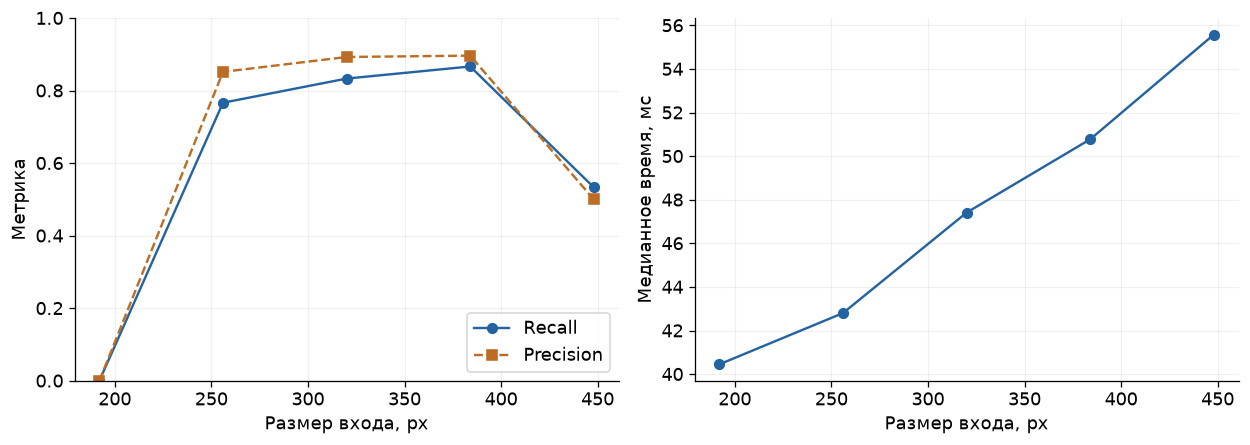

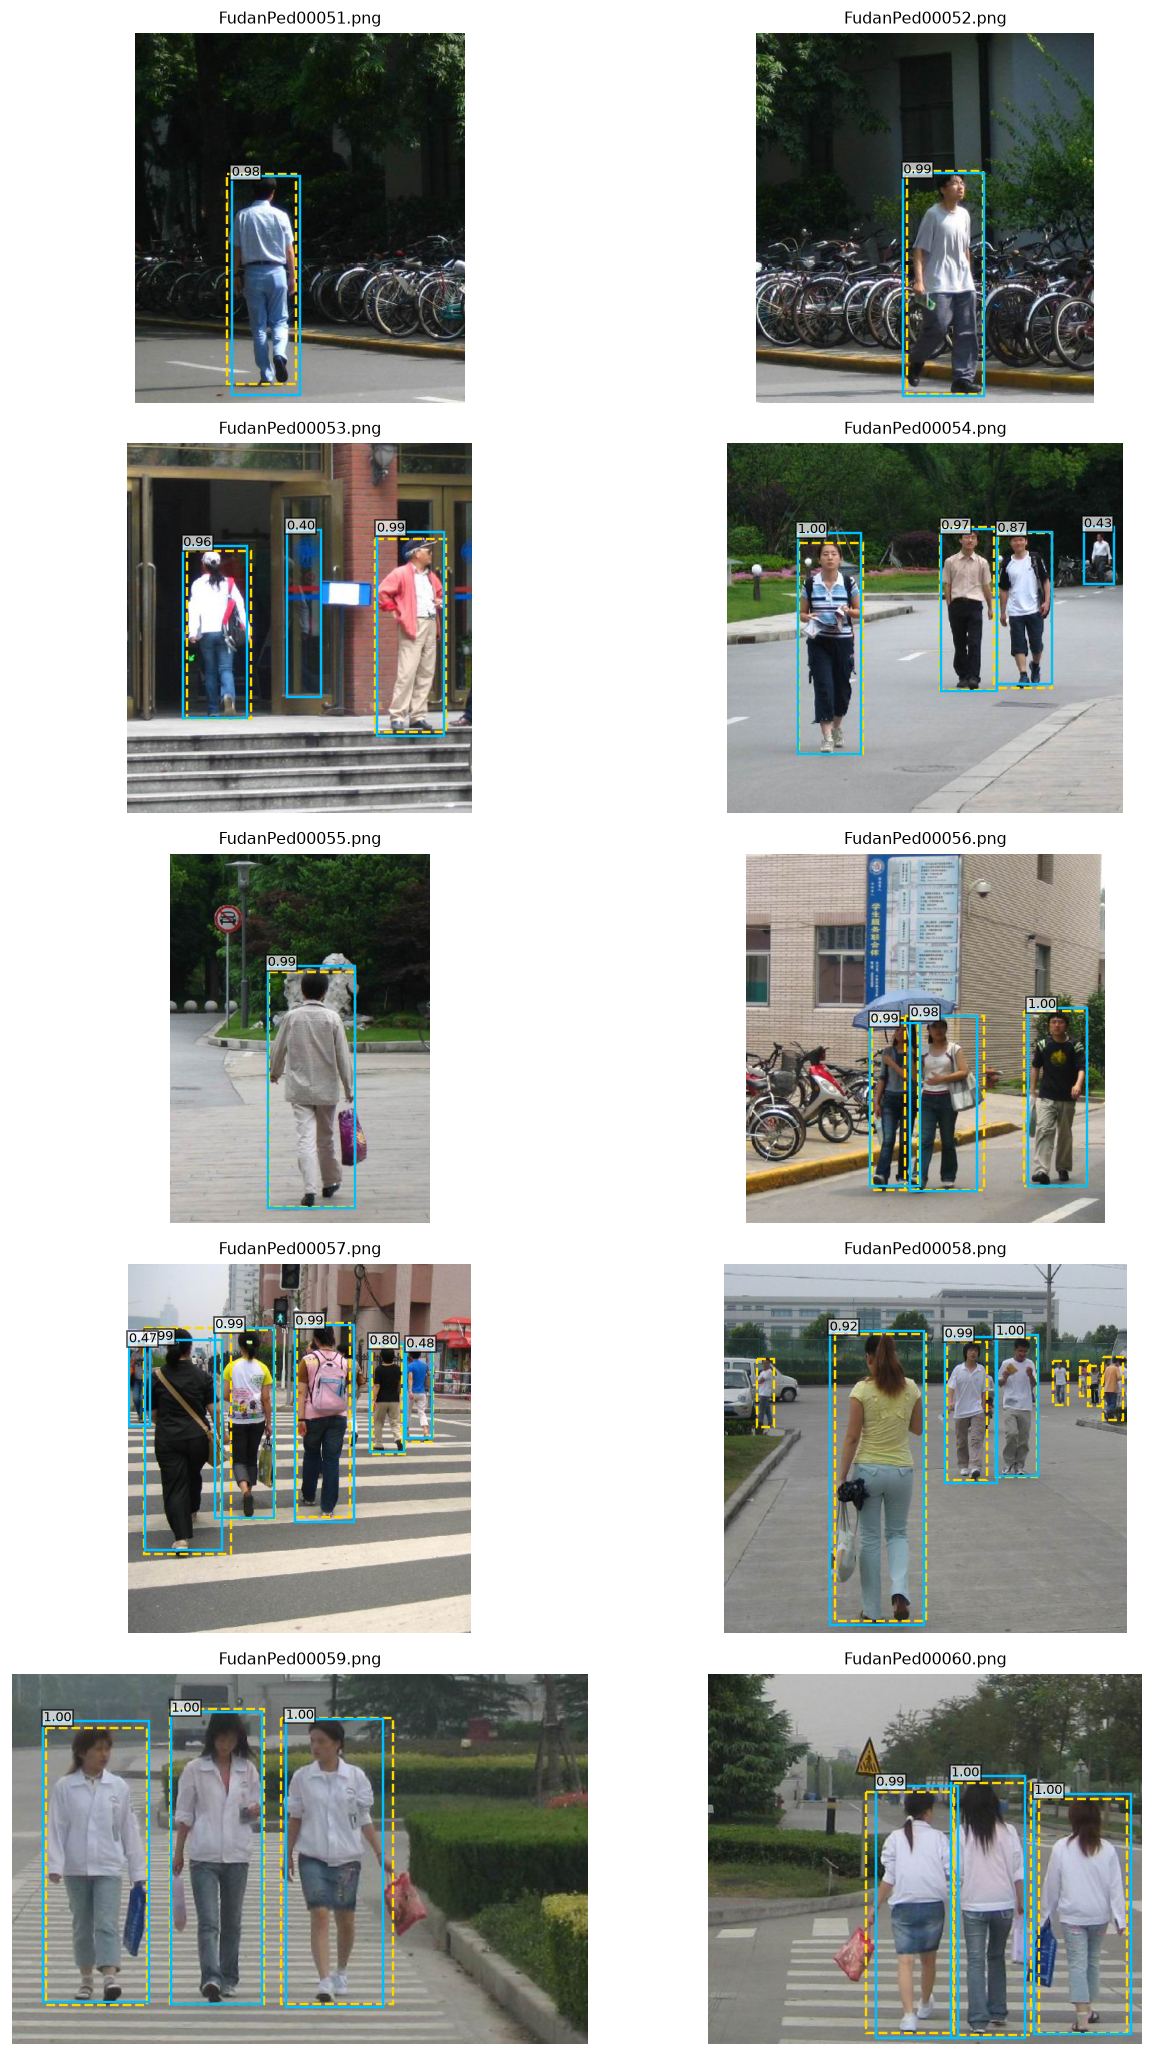

,image,confidence,x1,y1,x2,y2
0,FudanPed00051.png,0.97801,134.01802,197.10503,228.55347,501.45059
1,FudanPed00052.png,0.99283,203.10234,193.69472,314.61609,502.91867
2,FudanPed00053.png,0.99406,345.11844,121.85607,438.57172,405.63712
3,FudanPed00053.png,0.96174,76.81441,141.93773,164.71967,380.32831
4,FudanPed00053.png,0.40037,220.52170,118.90186,268.02213,351.41373
5,FudanPed00054.png,0.99778,90.68523,115.48312,172.18103,401.95117
6,FudanPed00054.png,0.97020,276.13766,110.47033,348.76755,320.28696
7,FudanPed00054.png,0.86619,348.77905,113.99405,419.96198,311.13727
8,FudanPed00054.png,0.42603,460.66406,108.10863,500.11719,181.38585
9,FudanPed00055.png,0.99428,134.85312,155.13139,255.48335,490.87115


Жёлтый пунктир — разметка, голубые рамки — SSD. FP — лишние рамки, FN — пропущенные люди, порог совпадения IoU=0.5. Mean matched IoU считается только по совпавшим рамкам. RSS включает весь процесс Python. SSDlite обучен на размере 320; при смене размера меняется также геометрия признаков и anchors. Ниже проверяю YOLO.

In [2]:
from vision import detection_experiment

detection = detection_experiment(OUT)

## Пороги confidence, NMS и ошибки

Сравниваю пороги confidence и NMS, считаю FP, FN и IoU для класса person. Совпадение рамок — IoU ≥ 0.5. Время измеряю после прогрева, память — через RSS процесса.

In [3]:
from vision import detection_thresholds

detection_thresholds(detection, OUT)

,threshold,TP,FP,FN
0,0.1,26,21,4
1,0.3,26,6,4
2,0.5,24,0,6
3,0.7,24,0,6
4,0.9,22,0,8


,NMS_IoU_threshold,TP,FP,FN,matched_IoU
0,0.3,1,0,0,0.83449
1,0.5,1,0,0,0.83449
2,0.7,1,0,0,0.83449


,image,TP,FP,FN,matched_IoU
0,FudanPed00051.png,1,0,0,0.83449
1,FudanPed00052.png,1,0,0,0.92511
2,FudanPed00053.png,2,1,0,0.87900
3,FudanPed00054.png,3,1,0,0.92546
4,FudanPed00055.png,1,0,0,0.95778
5,FudanPed00056.png,3,0,0,0.87821
6,FudanPed00057.png,5,1,0,0.85482
7,FudanPed00058.png,3,0,5,0.86126
8,FudanPed00059.png,3,0,0,0.91561
9,FudanPed00060.png,3,0,0,0.84913


Высокий confidence-порог убирает слабые рамки и увеличивает риск пропусков. Сильное NMS может удалить рамки соседних людей. Ошибки зависят от перекрытия и размера объектов.

## Дополнительная проверка разрешения: YOLO

Повторяю пять размеров на тех же фотографиях с YOLO. SSDlite обучен на размере 320, поэтому изменение его внутреннего разрешения также меняет геометрию признаков и anchors.

,size,TP,FP,FN,precision,recall,median_ms
0,192,26,1,4,0.96296,0.86667,6.26908
1,256,28,2,2,0.93333,0.93333,7.54771
2,320,29,2,1,0.93548,0.96667,9.30204
3,384,30,2,0,0.93750,1.00000,12.08875
4,448,30,3,0,0.90909,1.00000,13.25262


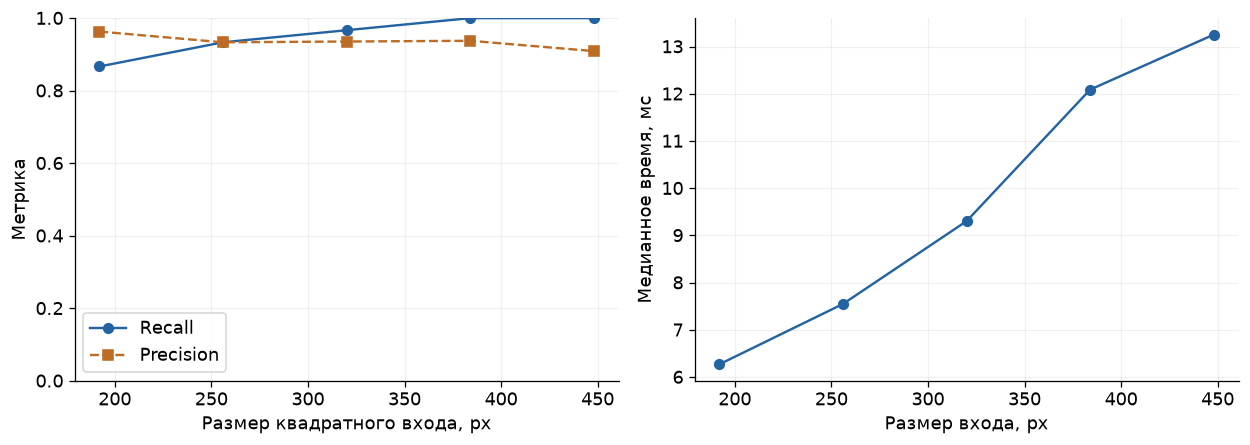

YOLO11n с весами COCO. Вход BGR, rect=False, person=0 переведён в person=1. Первый проход пропускаю при измерении времени. Для всех размеров использую одни десять фотографий и порог 0.4.

In [4]:
from additional import yolo_resolution

yolo_resolution(OUT)

## Сегментация U-Net и Dice

Объединяю маски отдельных людей в маску класса person. Сравниваю предсказание, разметку и границы. Test-изображения исключены из обучения.

,image,IoU,Dice
0,FudanPed00051.png,0.30109,0.46283
1,FudanPed00052.png,0.16368,0.28132
2,FudanPed00053.png,0.19263,0.32304
3,FudanPed00054.png,0.29046,0.45016
4,FudanPed00055.png,0.01460,0.02879
5,FudanPed00056.png,0.05329,0.10119
6,FudanPed00057.png,0.25153,0.40196
7,FudanPed00058.png,0.01035,0.02049
8,FudanPed00059.png,0.00000,0.00000
9,FudanPed00060.png,0.01145,0.02264


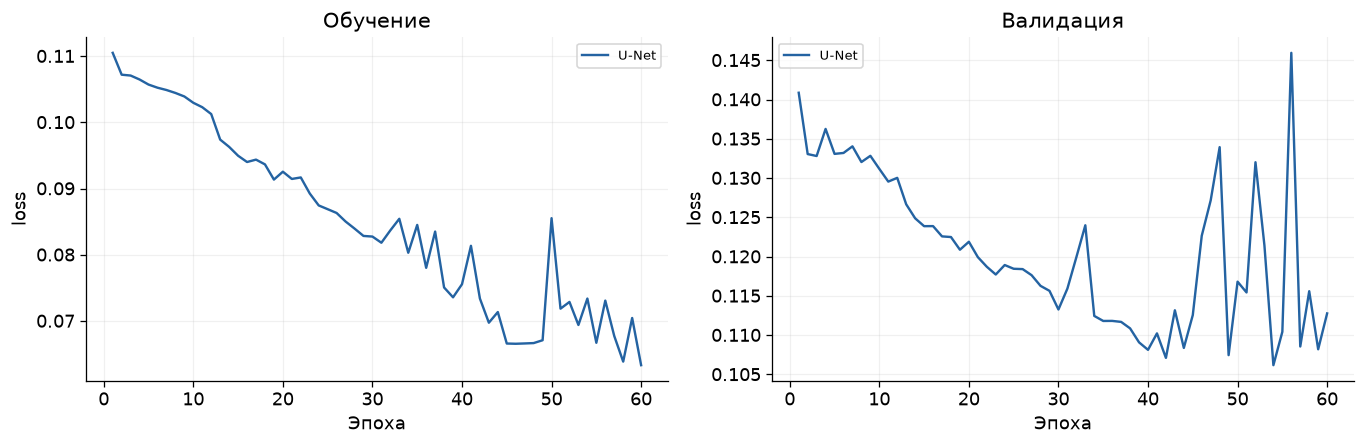

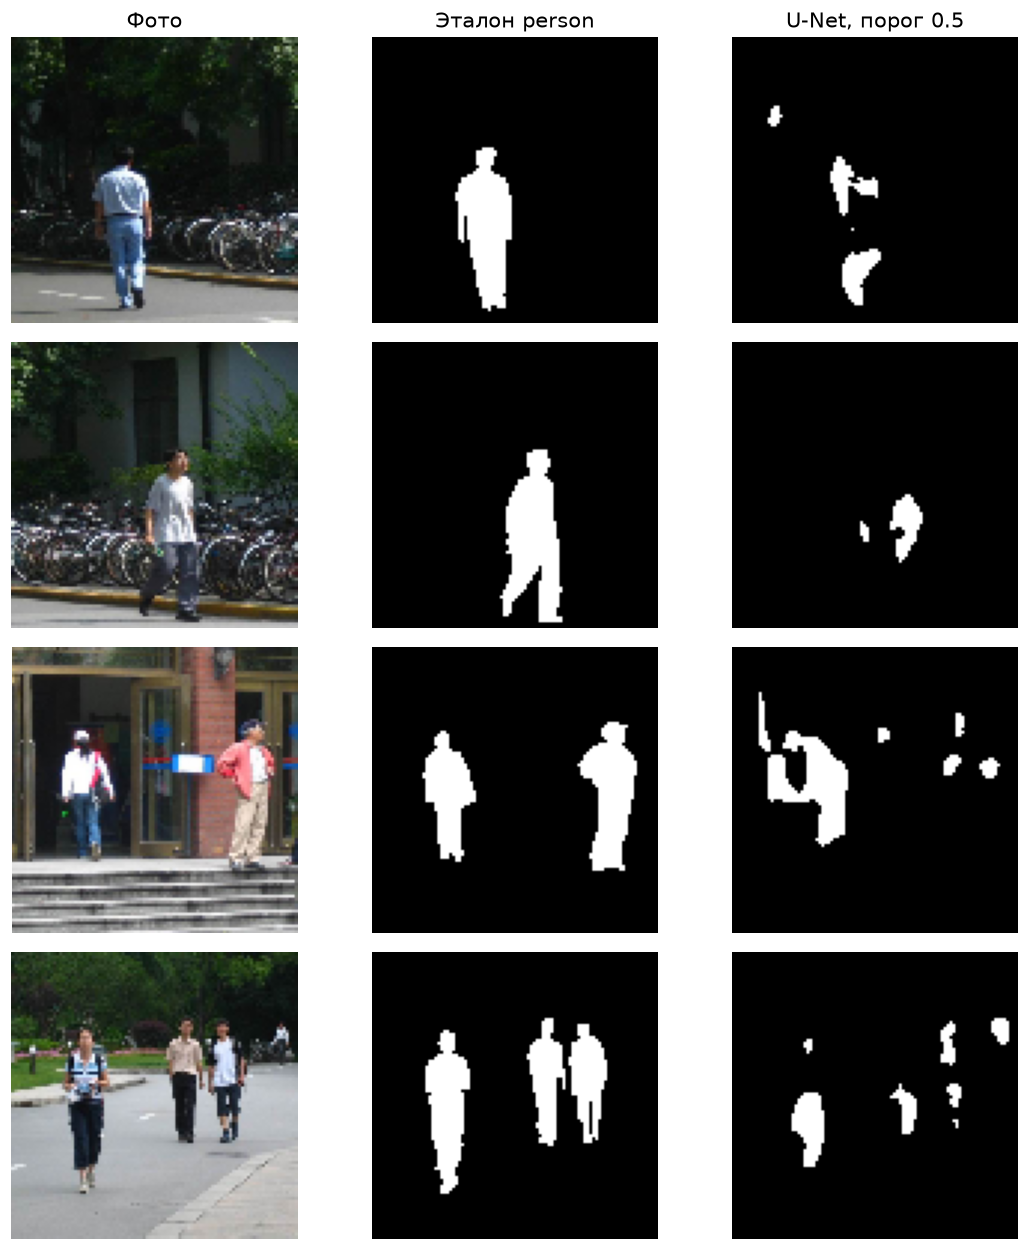

,image,boundary_precision_tolerance_2px,boundary_recall_tolerance_2px
0,0,0.48387,0.41844
1,1,0.45312,0.14545
2,2,0.32203,0.36239
3,3,0.68023,0.40122
4,4,0.29310,0.09890
5,5,0.33333,0.13386
6,6,0.67660,0.34646
7,7,0.57143,0.02209
8,8,0.00000,0.00000
9,9,0.26667,0.03942


Средние IoU=0.129, Dice=0.209 на десяти test-изображениях. На разрешении 96×96 тонкие конечности и мелкие объекты теряются. Tiny U-Net использует skip-связь и обучается с MSE по бинарной маске; BCE/Dice-loss, увеличение данных и разрешения являются направлениями улучшения. Здесь оценивается семантическая маска класса person, экземпляры людей объединены.

In [5]:
from vision import segmentation_experiment

segmentation_experiment(detection, OUT)

## Ответы на контрольные вопросы

1. Классификация предсказывает класс изображения; детекция добавляет координаты объектов и может выдать несколько результатов.

2. Confidence относится к внутренней уверенности модели и может быть некалиброванным; точность координат отдельно проверяется IoU.

3. NMS удаляет сильно перекрывающиеся рамки одного класса, уменьшая дубли; чрезмерное подавление может удалить соседние объекты.

4. Semantic segmentation выдаёт класс пикселя; instance segmentation дополнительно разделяет отдельные объекты одного класса.

5. Фон может занимать почти всё изображение, поэтому предсказание «везде фон» даёт высокую pixel accuracy при пропуске объекта.